<a href="https://colab.research.google.com/github/MateoCalvache/MateoCalvache_DM/blob/main/Entrega1_GlowUp_Radar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GlowUp Radar (Seoru) — Entrega 1
**Curso:** Minería de Datos · **Caso:** ¿Con qué importador entra Seoru a Colombia en 2027?

Primera vuelta de CRISP-DM: entendimiento del negocio y de los datos, preparación, modelos base y evaluación frente a la regla simple.

**Cómo correrlo:** sube `glowup_data.csv` a tu Drive (o a la carpeta de Colab) y ajusta `RUTA_DATOS` en la primera celda de código. No hace falta instalar nada: solo usa pandas, numpy, scikit-learn y matplotlib.

In [ ]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
SEED = 42
np.random.seed(SEED)

# ---- AJUSTAR AQUÍ LA RUTA DE LOS DATOS ----
# En Colab: from google.colab import drive; drive.mount('/content/drive')
CANDIDATAS = [
    "/content/drive/MyDrive/glowup_data.csv",
    "/content/drive/MyDrive/Proyecto Final/glowup_data.csv",
    "/content/glowup_data.csv",
    "glowup_data.csv",
    "../glowup_data.csv",
]
RUTA_DATOS = next((r for r in CANDIDATAS if os.path.exists(r)), CANDIDATAS[0])
if os.environ.get("RUTA_DATOS"):
    RUTA_DATOS = os.environ["RUTA_DATOS"]
os.makedirs("figs", exist_ok=True)
RES = {}   # resultados que se citan en el informe
df = pd.read_csv(RUTA_DATOS)
print("Archivo:", RUTA_DATOS, "->", df.shape)

Archivo: C:/Users/2004s/Desktop/Uni/Otro semestre/Mineria/Proyecto/glowup_data.csv -> (1773, 55)


## 1. Entendimiento del negocio
**Decisión.** Seoru debe elegir con qué importador colombiano negociar en 2027. Para cada uno: *firmar*, *firmar con garantías* o *no firmar*.
**Target.** `y_abandona = 1` si el valor CIF importado en t+1 es menos de la mitad del de t (no importar nada cuenta como abandono).
**Métrica.** Costo de los errores en US$ por cada 100 importadores evaluados, medido en la prueba (2024). Sensibilidad, precisión y AUC apoyan.

| Situación | Costo para Seoru (US$) |
|---|---|
| Firmar con uno que después abandona | 250.000 |
| No firmar con uno que sí habría funcionado | 50.000 |
| Firmar con garantías con uno que se queda | 20.000 |
| Firmar con garantías con uno que abandona | 120.000 |
| Firmar sin garantías con uno que se queda, o no firmar con uno que abandona | 0 |

Con estos costos los umbrales óptimos salen de igualar costos esperados: sin garantías si p < 13,3 %, con garantías entre 13,3 % y 20 %, no firmar si p > 20 % (con solo firmar / no firmar sería 16,7 %).

In [ ]:
# Matriz de costos: filas = realidad (0 se queda, 1 abandona); columnas = decisión (0 firmar, 1 firmar con garantías, 2 no firmar)
COSTO = np.array([[0, 20_000, 50_000],
                  [250_000, 120_000, 0]], dtype=float)
NOMBRE_DEC = {0: "Firmar", 1: "Firmar con garantías", 2: "No firmar"}

def decidir(p, t1, t2):
    """p < t1 firma; t1 <= p < t2 garantías; p >= t2 no firma."""
    p = np.asarray(p)
    return np.where(p < t1, 0, np.where(p < t2, 1, 2))

def costos_fila(y, dec):
    return COSTO[np.asarray(y).astype(int), np.asarray(dec).astype(int)]

def costo100(y, dec):
    return costos_fila(y, dec).mean() * 100

# Umbrales teóricos (igualando costos esperados)
T1_TEO = 20_000 / (250_000 - 100_000)          # firmar = garantías: 250p = 20+100p
T2_TEO = (50_000 - 20_000) / (50_000 + 100_000)  # garantías = no firmar: 20+100p = 50-50p
T_BIN_TEO = 50_000 / (250_000 + 50_000)
print(f"Umbral 1 (firmar -> garantías): {T1_TEO:.3f} | Umbral 2 (garantías -> no firmar): {T2_TEO:.3f} | binario: {T_BIN_TEO:.3f}")

Umbral 1 (firmar -> garantías): 0.133 | Umbral 2 (garantías -> no firmar): 0.200 | binario: 0.167


## 2. Entendimiento de los datos
### 2.1 Qué es una fila y tasa base

In [ ]:
print("Filas por año:\n", df.groupby("anio_t").size().to_string())
tb = df[df.anio_t < 2025].groupby("anio_t").y_abandona.agg(["count", "sum", "mean"])
tb.columns = ["filas", "abandonan", "tasa_base"]
print("\nTasa base de abandono (sin filtros):\n", tb.round(4).to_string())
print("\nNIT distintos:", df.nit.nunique(), "| filas sin NIT (personas naturales):", int(df.nit.isna().sum()))
print("CIF mínimo por fila:", round(df.cif_t.min(), 0))
RES["tasa_base_bruta"] = {int(a): float(r.tasa_base) for a, r in tb.iterrows()}

# Aprobar a todos / rechazar a todos, sin filtros, por 100 importadores
for a in (2023, 2024):
    y = df[df.anio_t == a].y_abandona.values
    RES[f"todos_firmar_{a}_bruto"] = costo100(y, np.zeros(len(y)))
    RES[f"todos_rechazar_{a}_bruto"] = costo100(y, np.full(len(y), 2))
print({k: round(v / 1e6, 2) for k, v in RES.items() if "todos" in k}, "(US$ millones por 100 importadores)")

Filas por año:
 anio_t
2023    574
2024    578
2025    621

Tasa base de abandono (sin filtros):
         filas  abandonan  tasa_base
anio_t                             
2023      574      124.0     0.2160
2024      578      113.0     0.1955

NIT distintos: 790 | filas sin NIT (personas naturales): 3
CIF mínimo por fila: 20012.0
{'todos_firmar_2023_bruto': np.float64(5.4), 'todos_rechazar_2023_bruto': np.float64(3.92), 'todos_firmar_2024_bruto': np.float64(4.89), 'todos_rechazar_2024_bruto': np.float64(4.02)} (US$ millones por 100 importadores)


### 2.2 Población: ¿quién entra al radar? (filtro por actividad económica)
No todos los importadores del capítulo 33 venden producto de consumo: hay fabricantes de insumos, empresas de logística, comercio de maquinaria, etc. Para Seoru un socio útil distribuye o fabrica **producto de consumo** (cosméticos, aseo, farmacia, alimentos y bebidas de consumo). El filtro se decide por reglas de negocio sobre el código CIIU (`ciiu_2` = división + grupo de 3 dígitos), **no mirando el target**, y se aplica igual en entrenamiento, prueba y radar.

- **Se quedan:** comercio al por mayor de consumo (461, 463, 464, 469), comercio al por menor (471–475, 477, 479), manufactura de cosméticos y aseo (202), farmacéutica (210) y servicios de belleza (960).
- **Se excluyen:** comercio de materias primas agropecuarias (462), maquinaria (465), otro mayorista especializado de insumos industriales (466), combustibles (473), repuestos (453), alimentos y demás manufactura distinta de 202/210, servicios profesionales y empresas sin actividad de consumo.
- Las 5 filas sin CIIU (incluidas 3 personas naturales) se **mantienen** con categoría "sin dato": el brief pide modelarlas, y la aplicación no mostrará su nombre ni NIT.

In [ ]:
CIIU_CONSUMO = {461, 463, 464, 469, 471, 472, 474, 475, 477, 479, 202, 210, 960}
conteo = []
d0 = df.copy()
conteo.append(("Archivo completo", d0))
d1 = d0[d0.cif_t >= 20_000]
conteo.append(("CIF >= US$20.000 (ya aplicado en el archivo)", d1))
d2 = d1[d1.ciiu_2.isna() | d1.ciiu_2.isin(CIIU_CONSUMO)].copy()
conteo.append(("Producto de consumo según CIIU (+ sin dato)", d2))
filas = []
for nom, d in conteo:
    r = {"paso": nom}
    for a in (2023, 2024, 2025):
        r[str(a)] = int((d.anio_t == a).sum())
    r["total"] = len(d)
    filas.append(r)
tabla_filtros = pd.DataFrame(filas)
print(tabla_filtros.to_string(index=False))
RES["filtros"] = filas

tb2 = d2[d2.anio_t < 2025].groupby("anio_t").y_abandona.agg(["count", "sum", "mean"])
print("\nTasa base tras el filtro:\n", tb2.round(4).to_string())
RES["tasa_base_filtrada"] = {int(a): float(r["mean"]) for a, r in tb2.iterrows()}
RES["n_filtrada"] = {int(a): int(r["count"]) for a, r in tb2.iterrows()}
RES["abandonan_filtrada"] = {int(a): int(r["sum"]) for a, r in tb2.iterrows()}

data = d2.reset_index(drop=True)
# ID de grupo para validación cruzada (NIT; las personas naturales sin NIT reciben un id único)
data["grupo"] = data.nit.fillna(-1).astype(float)
sin_nit = data.nit.isna()
data.loc[sin_nit, "grupo"] = -1 - np.arange(sin_nit.sum())

tr = data[data.anio_t == 2023].copy()
te = data[data.anio_t == 2024].copy()
rd = data[data.anio_t == 2025].copy()
print("\nEntrenamiento 2023:", len(tr), "| Prueba 2024:", len(te), "| Radar 2025:", len(rd))

                                        paso  2023  2024  2025  total
                            Archivo completo   574   578   621   1773
CIF >= US$20.000 (ya aplicado en el archivo)   574   578   621   1773
 Producto de consumo según CIIU (+ sin dato)   458   453   490   1401

Tasa base tras el filtro:
         count    sum    mean
anio_t                      
2023      458  102.0  0.2227
2024      453   91.0  0.2009

Entrenamiento 2023: 458 | Prueba 2024: 453 | Radar 2025: 490


### 2.3 Faltantes

In [ ]:
falt = data.isna().sum()
falt = falt[falt > 0].to_frame("faltantes")
falt["pct"] = (falt.faltantes / len(data) * 100).round(1)
print(falt.sort_values("faltantes", ascending=False).to_string())
# ¿Por qué falta el texto? Se relaciona con no tener notificaciones nuevas?
print("\nFilas con texto vacío:", int(data.texto_productos_t.isna().sum()))
print("  de ellas con reg_t == 0 (sin notificaciones nuevas):", int(((data.texto_productos_t.isna()) & (data.reg_t == 0)).sum()))
print("  de ellas con todas las categorías en 0:", int(((data.texto_productos_t.isna()) & (data[[c for c in data.columns if c.startswith('cat_') and c != 'cat_oral' or c == 'cat_oral']].sum(axis=1) == 0)).sum()))
print("Filas con texto y reg_t == 0:", int(((data.texto_productos_t.notna()) & (data.reg_t == 0)).sum()))
RES["texto_vacio_pct"] = float(data.texto_productos_t.isna().mean() * 100)

                     faltantes   pct
yt_n_coment               1368  97.6
yt_sent_neto              1368  97.6
yt_intencion_compra       1368  97.6
yt_like_rate              1351  96.4
yt_log_views              1351  96.4
yt_canales                1351  96.4
yt_img_brillo             1351  96.4
yt_img_saturacion         1351  96.4
yt_img_colorido           1351  96.4
yt_img_rosa               1351  96.4
yt_videos_rel             1321  94.3
yt_share_relevante        1321  94.3
yt_consultado             1321  94.3
texto_productos_t          682  48.7
cif_t1                     490  35.0
ratio_t1                   490  35.0
y_crece                    490  35.0
y_abandona                 490  35.0
edad_anios_t                 5   0.4
camara_bogota                5   0.4
ciiu_2                       5   0.4
ciiu_letra                   5   0.4
forma                        5   0.4
nit                          3   0.2

Filas con texto vacío: 682
  de ellas con reg_t == 0 (sin notificaciones n

**Decisión sobre los faltantes.** El texto vacío no es un error: significa que ese año el importador no notificó productos nuevos ante el INVIMA, y por eso las proporciones por categoría valen 0. Se conserva el 0 y se agrega un indicador `tiene_texto`. Los 5 faltantes de `edad_anios_t`, `forma`, `ciiu_*` y `camara_bogota` vienen de las filas sin registro mercantil; la edad se imputa con la **mediana del entrenamiento (2023)** y las categorías pasan a "sin dato".

### 2.4 Distribución del valor importado y tasa de abandono por grupos

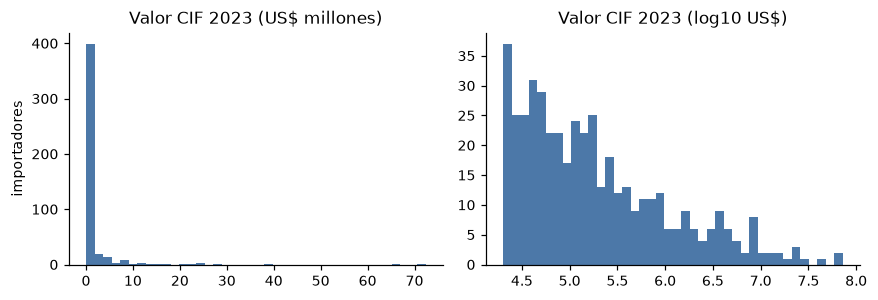

count         458.0
mean      1469186.0
std       5778544.0
min         20137.0
50%        123656.0
90%       3074914.0
99%      24002675.0
max      72374423.0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].hist(tr.cif_t / 1e6, bins=40, color="#4c78a8"); ax[0].set_title("Valor CIF 2023 (US$ millones)"); ax[0].set_ylabel("importadores")
ax[1].hist(np.log10(tr.cif_t), bins=40, color="#4c78a8"); ax[1].set_title("Valor CIF 2023 (log10 US$)")
plt.tight_layout(); plt.savefig("figs/f1_distribucion_cif.png", dpi=160); plt.show()
print(tr.cif_t.describe(percentiles=[.5, .9, .99]).round(0).to_string())

**Lectura.** La distribución del valor importado es muy sesgada: la mediana de 2023 es ~US$124 mil, el 10 % superior importa más de US$3,1 millones y el máximo pasa de US$72 millones. En escala logarítmica queda casi simétrica, por eso el modelo usa el logaritmo y no el valor crudo. *Para Seoru:* el mercado es de muchos importadores pequeños y pocos grandes; "tamaño" no es una sola cosa.

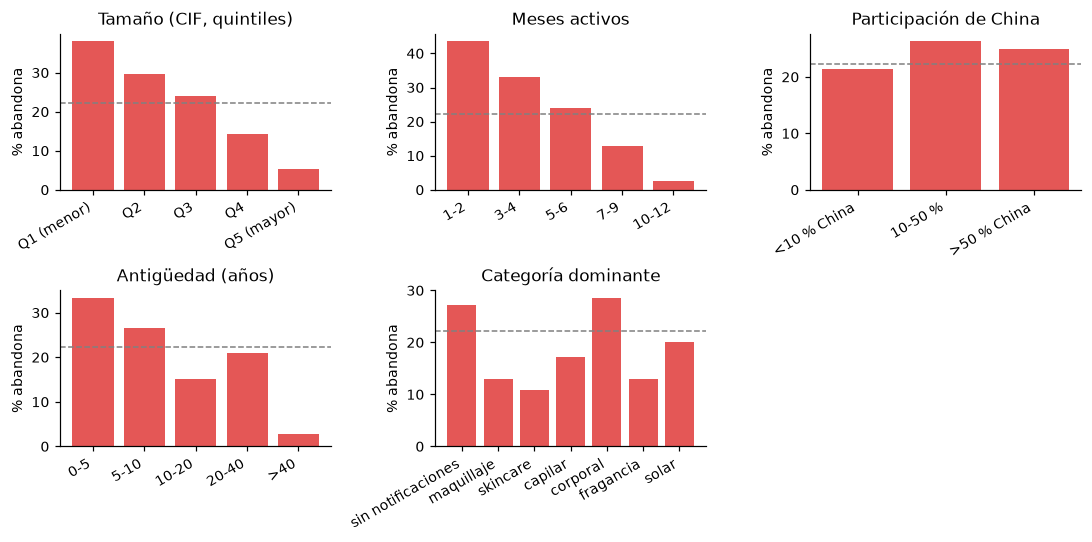


 tamaño
            count   mean
tam                     
Q1 (menor)     92  0.380
Q2             91  0.297
Q3             92  0.239
Q4             91  0.143
Q5 (mayor)     92  0.054

 meses activos
                     n  tasa_abandono
n_meses_activos_t                    
1-2                101          0.436
3-4                 91          0.330
5-6                 54          0.241
7-9                 94          0.128
10-12              118          0.025

 China
                 n  tasa_abandono
share_china_t                    
<10 % China    359          0.214
10-50 %         19          0.263
>50 % China     80          0.250

 antigüedad
                n  tasa_abandono
edad_anios_t                    
0-5           105          0.333
5-10          117          0.265
10-20         113          0.150
20-40          86          0.209
>40            35          0.029

 categoría
                    count   mean
cat_dom                         
sin notificaciones    247  0.271
m

In [ ]:
def tasa_por(col, bins=None, labels=None, base=tr):
    g = pd.cut(base[col], bins=bins, labels=labels, include_lowest=True) if bins is not None else base[col]
    t = base.groupby(g, observed=True).y_abandona.agg(["count", "mean"])
    t.columns = ["n", "tasa_abandono"]
    return t

q = tr.cif_t.quantile([0, .2, .4, .6, .8, 1]).values
base = tr.copy()
base["tam"] = pd.qcut(base.cif_t, 5, labels=["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (mayor)"])
t_tam = base.groupby("tam", observed=True).y_abandona.agg(["count", "mean"])
t_mes = tasa_por("n_meses_activos_t", bins=[0, 2, 4, 6, 9, 12], labels=["1-2", "3-4", "5-6", "7-9", "10-12"])
t_chi = tasa_por("share_china_t", bins=[-0.01, 0.1, 0.5, 1.0], labels=["<10 % China", "10-50 %", ">50 % China"])
t_edad = tasa_por("edad_anios_t", bins=[0, 5, 10, 20, 40, 100], labels=["0-5", "5-10", "10-20", "20-40", ">40"])
cats = [c for c in tr.columns if c.startswith("cat_") and c != "n_categorias_t"]
tr_cat = tr.copy()
tr_cat["cat_dom"] = np.where(tr_cat[cats].sum(axis=1) == 0, "sin notificaciones", tr_cat[cats].idxmax(axis=1).str.replace("cat_", ""))
t_cat = tr_cat.groupby("cat_dom").y_abandona.agg(["count", "mean"]).sort_values("count", ascending=False)

fig, axs = plt.subplots(2, 3, figsize=(10, 5))
for ax, (tt, tit) in zip(axs.ravel(), [(t_tam, "Tamaño (CIF, quintiles)"), (t_mes, "Meses activos"), (t_chi, "Participación de China"),
                                      (t_edad, "Antigüedad (años)"), (t_cat.head(7), "Categoría dominante")]):
    col = "mean" if "mean" in tt.columns else "tasa_abandono"
    ax.bar(range(len(tt)), tt[col] * 100, color="#e45756")
    ax.set_xticks(range(len(tt))); ax.set_xticklabels([str(i) for i in tt.index], rotation=30, ha="right")
    ax.axhline(tr.y_abandona.mean() * 100, ls="--", c="gray", lw=1)
    ax.set_title(tit); ax.set_ylabel("% abandona")
axs[1, 2].axis("off")
plt.tight_layout(); plt.savefig("figs/f2_tasa_por_grupos.png", dpi=160); plt.show()
for nom, tt in [("tamaño", t_tam), ("meses activos", t_mes), ("China", t_chi), ("antigüedad", t_edad), ("categoría", t_cat)]:
    print("\n", nom); print(tt.round(3).to_string())
RES["tasa_tamano"] = {str(k): float(v) for k, v in t_tam["mean"].items()}
RES["tasa_meses"] = {str(k): float(v) for k, v in t_mes["tasa_abandono"].items()}
RES["tasa_edad"] = {str(k): float(v) for k, v in t_edad["tasa_abandono"].items()}
RES["tasa_china"] = {str(k): float(v) for k, v in t_chi["tasa_abandono"].items()}

**Lectura.** El abandono baja de forma clara con la **constancia** y la **escala**: de 43,6 % entre quienes importan 1–2 meses al año a 2,5 % entre quienes importan 10–12 meses; y de 38 % en el quintil más pequeño por valor a 5 % en el más grande. También baja con la antigüedad (33 % en empresas de 0–5 años; 2,9 % en las de más de 40). La participación de China casi no separa (21–26 %). *Para Seoru:* la regla de "constancia" de un comprador experimentado tiene sustento en los datos; el origen del producto importa poco para el riesgo de abandono. Ojo: la categoría "sin notificaciones" (247 de 458) tiene 27 % de abandono frente a 11–13 % de skincare, maquillaje y fragancia, lo que sugiere que haber notificado productos al INVIMA ata al importador al negocio.

### 2.5 Diagramas de caja y correlaciones (entrenamiento 2023)

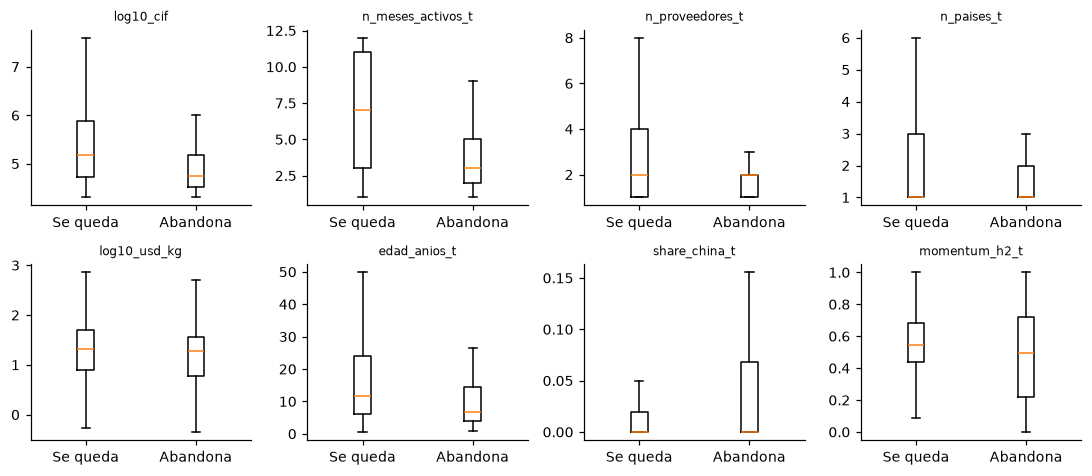

In [ ]:
tr_b = tr.copy()
tr_b["log10_cif"] = np.log10(tr_b.cif_t)
tr_b["log10_usd_kg"] = np.log10(tr_b.usd_por_kg_t.clip(lower=0.01))
vars_box = ["log10_cif", "n_meses_activos_t", "n_proveedores_t", "n_paises_t", "log10_usd_kg", "edad_anios_t", "share_china_t", "momentum_h2_t"]
fig, axs = plt.subplots(2, 4, figsize=(10, 4.4))
for ax, v in zip(axs.ravel(), vars_box):
    ax.boxplot([tr_b.loc[tr_b.y_abandona == 0, v].dropna(), tr_b.loc[tr_b.y_abandona == 1, v].dropna()], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Se queda", "Abandona"])
    ax.set_title(v, fontsize=8)
plt.tight_layout(); plt.savefig("figs/f3_cajas.png", dpi=160); plt.show()

**Lectura.** Quienes abandonan tienen la mediana más baja en meses activos, valor importado, proveedores, países y antigüedad: son importadores más pequeños, menos constantes y más jóvenes. El precio por kilo y la participación de China casi no los distinguen.

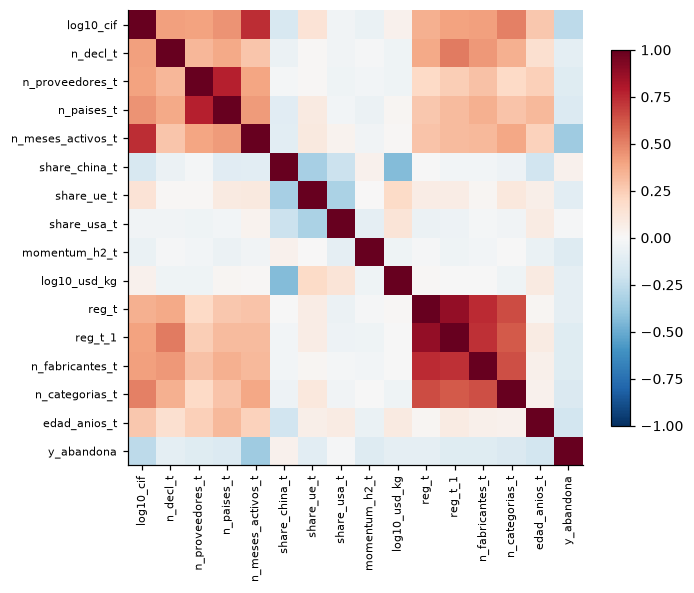

Correlaciones con y_abandona:
 n_meses_activos_t   -0.352
log10_cif           -0.263
edad_anios_t        -0.182
n_categorias_t      -0.146
n_paises_t          -0.133
momentum_h2_t       -0.132
reg_t_1             -0.123
n_fabricantes_t     -0.121
n_proveedores_t     -0.121
share_ue_t          -0.102
n_decl_t            -0.097
reg_t               -0.093
log10_usd_kg        -0.087
share_usa_t         -0.015
share_china_t        0.040

Pares más correlacionados:
 reg_t            reg_t_1              0.88
n_proveedores_t  n_paises_t           0.77
reg_t            n_fabricantes_t      0.75
log10_cif        n_meses_activos_t    0.74
reg_t_1          n_fabricantes_t      0.73


In [ ]:
num_cols = ["log10_cif", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t", "share_ue_t", "share_usa_t",
            "momentum_h2_t", "log10_usd_kg", "reg_t", "reg_t_1", "n_fabricantes_t", "n_categorias_t", "edad_anios_t", "y_abandona"]
C = tr_b[num_cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols, fontsize=7)
plt.colorbar(im, shrink=.8); plt.tight_layout(); plt.savefig("figs/f4_correlaciones.png", dpi=160); plt.show()
print("Correlaciones con y_abandona:\n", C["y_abandona"].drop("y_abandona").sort_values().round(3).to_string())
pares = C.drop(index="y_abandona", columns="y_abandona").abs().where(np.triu(np.ones((len(num_cols) - 1,) * 2), 1) == 1).stack().sort_values(ascending=False).head(5)
print("\nPares más correlacionados:\n", pares.round(2).to_string())

**Lectura.** La variable más asociada al abandono es `n_meses_activos_t` (−0,35), seguida por el valor importado (−0,26) y la antigüedad (−0,18). Hay redundancia fuerte entre `reg_t` y `reg_t_1` (0,88), proveedores y países (0,77) y entre valor y meses activos (0,74): por eso en la regresión logística se usa regularización y no se meten juntas versiones de la misma variable.

### 2.6 Detector de fuga
Se calcula el AUC de cada variable **sola** para ordenar a quienes abandonan, usando solo el entrenamiento (2023). Un AUC muy cercano a 1 (o a 0, con relación inversa) indica sospecha. Se incluyen a propósito las columnas que el diccionario marca como FUGA para ver cómo se ve una fuga.

                        AUC_solo  distancia_a_0.5
ratio_t1                   0.000            0.500
cif_t1                     0.067            0.433
n_meses_activos_t          0.258            0.242
n_decl_t                   0.295            0.205
cif_t                      0.318            0.182
edad_anios_t               0.362            0.138
n_proveedores_t            0.389            0.111
n_fabricantes_t            0.398            0.102
reg_t_1                    0.403            0.097
n_categorias_t             0.404            0.096
reg_t                      0.405            0.095
cat_maquillaje             0.410            0.090
cat_skincare               0.412            0.088
camara_bogota              0.417            0.083
share_fab_extranjero_t     0.423            0.077
momentum_h2_t              0.425            0.075
share_ue_t                 0.428            0.072
n_paises_t                 0.429            0.071
usd_por_kg_t               0.446            0.054


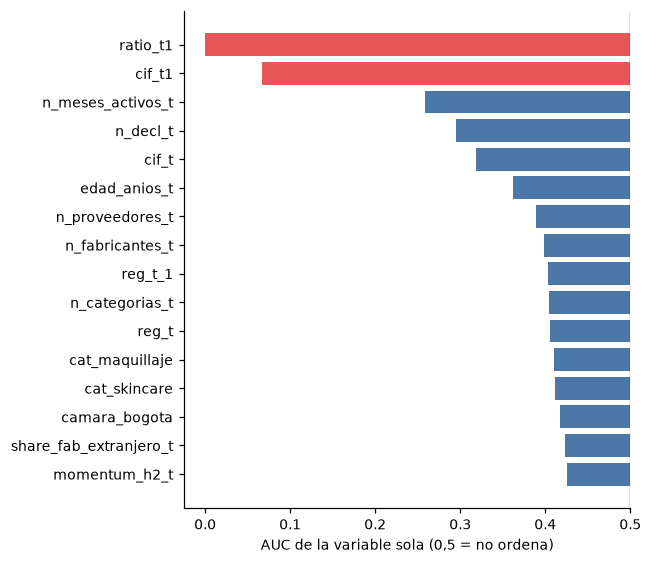

n_grafias_razon: tasa de abandono por valor -> {1: {'count': 386, 'mean': 0.231}, 2: {'count': 69, 'mean': 0.188}, 3: {'count': 2, 'mean': 0.0}, 4: {'count': 1, 'mean': 0.0}}
tiene_invima: tasa de abandono por valor -> {0: {'count': 139, 'mean': 0.273}, 1: {'count': 319, 'mean': 0.201}}
camara_bogota: tasa de abandono por valor -> {0.0: {'count': 187, 'mean': 0.294}, 1.0: {'count': 269, 'mean': 0.175}}


In [ ]:
def auc_solo(d, col):
    s = d[[col, "y_abandona"]].dropna()
    if s[col].nunique() < 2: return np.nan
    return roc_auc_score(s.y_abandona, s[col])

cand = ["cif_t1", "ratio_t1", "cif_t", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t", "share_ue_t", "share_usa_t",
        "momentum_h2_t", "usd_por_kg_t", "reg_t", "reg_t_1", "reg_crec", "n_fabricantes_t", "n_categorias_t", "edad_anios_t", "camara_bogota",
        "n_grafias_razon", "tiene_invima", "share_fab_china_t", "share_fab_extranjero_t"] + cats
aucs = pd.Series({c: auc_solo(tr, c) for c in cand}).sort_values()
aucs_df = pd.DataFrame({"AUC_solo": aucs.round(3), "distancia_a_0.5": (aucs - .5).abs().round(3)}).sort_values("distancia_a_0.5", ascending=False)
print(aucs_df.to_string())
RES["auc_solo"] = {k: float(v) for k, v in aucs.items()}

fig, ax = plt.subplots(figsize=(6, 5.2))
top = aucs_df.head(16).iloc[::-1]
ax.barh(top.index, top.AUC_solo - .5, left=.5, color=["#e45756" if i in ("cif_t1", "ratio_t1") else "#4c78a8" for i in top.index])
ax.axvline(.5, c="k", lw=.8); ax.set_xlabel("AUC de la variable sola (0,5 = no ordena)")
plt.tight_layout(); plt.savefig("figs/f5_auc_fuga.png", dpi=160); plt.show()

# Texto con "fuga en t+1": ¿alguna variable de contexto delata el desenlace?
for c in ["n_grafias_razon", "tiene_invima", "camara_bogota"]:
    print(f"{c}: tasa de abandono por valor ->", tr.groupby(c).y_abandona.agg(["count", "mean"]).round(3).to_dict("index"))

**Lectura del detector.** `ratio_t1` (AUC 0,00) y `cif_t1` (0,07) separan casi perfectamente porque *son* el desenlace (describen t+1): fuera. Entre las demás, las más informativas son constancia y escala (`n_meses_activos_t` AUC 0,26, `n_decl_t` 0,30, `cif_t` 0,32; el AUC es <0,5 porque más actividad = menos abandono). Ninguna llega a niveles sospechosos, así que no hay fuga evidente en las demás.

**Columnas excluidas de la entrada del modelo y por qué**
- `cif_t1`, `ratio_t1`: FUGA (describen t+1). `y_crece`: target alterno (derivado de t+1). `y_abandona`: target.
- `nit`, `anio_t`: identificadores. `razon_social`: texto libre, contexto.
- `n_grafias_razon` (AUC 0,48, sin información): se calcula sobre todo el registro de aduana, que puede incluir años posteriores a t; se excluye por precaución.
- `tiene_invima` (AUC 0,46): no dice hasta qué fecha se unieron las notificaciones; se excluye por precaución.
- `yt_*`: solo existen para 84 importadores en 2024 (el año de prueba); no pueden entrar al modelo del radar.
- `ciiu_letra`, `forma`, `camara_bogota` vienen de un registro mercantil actual y podrían reflejar cambios posteriores a t. Se conservan porque su lógica de negocio es clara y su AUC es moderado (`camara_bogota` 0,42), y se marcan como riesgo residual en *Límites*.

**Lectura del detector.** `cif_t1` y `ratio_t1` separan casi perfectamente porque *son* el desenlace (describen t+1): quedan fuera. Ninguna otra variable llega a niveles sospechosos; las más informativas son constancia y escala (meses activos, valor importado), lo cual tiene sentido de negocio.

**Columnas excluidas de la entrada del modelo y por qué**
- `cif_t1`, `ratio_t1`: FUGA (describen t+1). `y_crece`: target alterno (derivado de t+1). `y_abandona`: target.
- `nit`, `anio_t`: identificadores. `razon_social`: texto libre, contexto.
- `n_grafias_razon`: se calcula sobre todo el registro de aduana, que puede incluir años posteriores a t; se excluye por precaución.
- `tiene_invima`: no dice hasta qué fecha se unieron las notificaciones; se excluye por precaución.
- `yt_*`: solo existen para 84 importadores en 2024 (el año de prueba); no pueden entrar al modelo del radar.
- `ciiu_letra`, `forma`, `camara_bogota` vienen de un registro mercantil actual y podrían reflejar cambios posteriores a t. Se conservan porque su AUC solo es bajo y su lógica de negocio es clara, pero se marcan como riesgo residual en *Límites*.

## 3. Preparación de los datos
Todo lo que se "aprende" (percentil 99 para recortar, mediana de imputación, escalado, hiperparámetros, cortes de la regla y umbrales) se calcula **solo con 2023**. La prueba (2024) se usa una vez, al final.

### 3.1 Variables construidas

In [ ]:
KEYS = ["SERUM", "SÉRUM", "NIACINAMIDA", "HIALURON", "LIMPIADOR FACIAL", "PROTECTOR SOLAR", "FILTRO SOLAR", "BLOQUEADOR"]
def afinidad(txt):
    if not isinstance(txt, str) or not txt.strip(): return 0.0
    items = [t.strip().upper() for t in txt.split("|") if t.strip()]
    return float(np.mean([any(k in it for k in KEYS) for it in items])) if items else 0.0

def construir(d):
    d = d.copy()
    d["intensidad_sanitaria"] = np.where(d.cif_t > 0, d.reg_t / (d.cif_t / 1e6), 0.0)            # notificaciones nuevas por millón de US$
    d["valor_por_mes"] = d.cif_t / d.n_meses_activos_t.clip(lower=1)                               # US$ por mes activo
    d["decl_por_proveedor"] = d.n_decl_t / d.n_proveedores_t.clip(lower=1)                         # repetición de la relación con proveedores
    d["afinidad_seoru"] = d.texto_productos_t.apply(afinidad)                                      # 0 si no hay texto (sin notificaciones)
    d["tiene_texto"] = d.texto_productos_t.notna().astype(int)
    return d

tr, te, rd = construir(tr), construir(te), construir(rd)
nuevas = ["intensidad_sanitaria", "valor_por_mes", "decl_por_proveedor", "afinidad_seoru"]

# Evidencia: tasa de abandono por cuartiles (cortes del entrenamiento) para las tres primeras; por presencia para afinidad
filas = []
for v in nuevas[:3]:
    g = pd.qcut(tr[v].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
    t = tr.groupby(g, observed=True).y_abandona.mean()
    filas.append({"variable": v, **{k: round(float(x), 3) for k, x in t.items()}, "AUC_sola": round(auc_solo(tr, v), 3)})
g = np.where(tr.afinidad_seoru > 0, "con afinidad", "sin afinidad")
t = tr.groupby(g).y_abandona.agg(["count", "mean"])
filas.append({"variable": "afinidad_seoru", "Q1": round(float(t.loc["sin afinidad", "mean"]), 3), "Q4": round(float(t.loc["con afinidad", "mean"]), 3), "AUC_sola": round(auc_solo(tr, "afinidad_seoru"), 3)})
ev = pd.DataFrame(filas)
print(ev.to_string(index=False))
print("\nImportadores con afinidad > 0 en 2023:", int((tr.afinidad_seoru > 0).sum()), "de", len(tr))
RES["evidencia_vars"] = filas
RES["afinidad_con"] = int((tr.afinidad_seoru > 0).sum())

            variable    Q1    Q2    Q3    Q4  AUC_sola
intensidad_sanitaria 0.183 0.360 0.105 0.243     0.464
       valor_por_mes 0.235 0.281 0.254 0.122     0.414
  decl_por_proveedor 0.383 0.219 0.167 0.122     0.327
      afinidad_seoru 0.245   NaN   NaN 0.107     0.445

Importadores con afinidad > 0 en 2023: 75 de 458


**Lectura de la evidencia.** `decl_por_proveedor` es la mejor variable nueva: el abandono baja de 38 % (Q1) a 12 % (Q4) y su AUC sola es 0,33, mejor que `valor_por_mes` (0,41). `afinidad_seoru` sirve para ordenar candidatos: entre los 75 importadores con afinidad > 0 el abandono es 10,7 %, frente a 24,5 % sin afinidad. `intensidad_sanitaria` **no** muestra una relación ordenada con el abandono (18 %, 36 %, 11 %, 24 % por cuartil; AUC 0,46): la dejamos en el modelo pero no podemos afirmar que aporte; así consta en *Límites*.

**Lógica de negocio de cada variable**
- `intensidad_sanitaria` = notificaciones nuevas por millón de US$ importado: separa al que invierte en ampliar portafolio del que solo mueve volumen. Si el denominador es 0 se pone 0.
- `valor_por_mes` = US$ por mes activo: distingue al grande y constante del que hace una sola compra grande al año.
- `decl_por_proveedor` = declaraciones / proveedores: alto = relaciones repetidas (estabilidad); bajo = compras sueltas. Si hay 0 proveedores se divide por 1.
- `afinidad_seoru` = proporción de productos notificados cuyo nombre incluye sérum, niacinamida, hialurónico, limpiador facial o protector solar. Sirve sobre todo para **ordenar candidatos** (encaje con Seoru) más que para predecir abandono; en la entrega final se usa para elegir los 20 de diligencia.

### 3.2 Recorte de atípicos, imputación y matriz de modelado

In [ ]:
# Percentil 99 del entrenamiento para variables de cola larga (los valores grandes pero reales se limitan, no se borran)
A_RECORTAR = ["cif_t", "n_decl_t", "n_proveedores_t", "usd_por_kg_t", "valor_por_mes", "intensidad_sanitaria", "decl_por_proveedor", "n_fabricantes_t", "reg_t", "reg_t_1"]
P99 = {c: float(tr[c].quantile(.99)) for c in A_RECORTAR}
MEDIANA_EDAD = float(tr.edad_anios_t.median())
print("Percentil 99 (2023):", {k: round(v, 1) for k, v in P99.items()}, "| mediana edad:", round(MEDIANA_EDAD, 1))

NUM = ["log_cif", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t", "share_ue_t", "share_usa_t", "momentum_h2_t",
       "log_usd_kg", "reg_t", "reg_t_1", "n_fabricantes_t", "n_categorias_t", "share_fab_china_t", "share_fab_extranjero_t", "edad_anios_t",
       "camara_bogota", "tiene_texto", "log_valor_mes", "intensidad_sanitaria", "decl_por_proveedor", "afinidad_seoru"] + cats
FORMAS = ["SOCIEDADES POR ACCIONES SIMPLIFICADAS", "ANONIMA", "LIMITADA", "OTRA"]
CIIU_G = sorted(int(x) for x in tr.ciiu_letra.dropna().unique())

def preparar(d):
    d = d.copy()
    for c in A_RECORTAR: d[c] = d[c].clip(upper=P99[c])
    d["edad_anios_t"] = d.edad_anios_t.fillna(MEDIANA_EDAD)
    d["camara_bogota"] = d.camara_bogota.fillna(0)
    d["log_cif"] = np.log10(d.cif_t)
    d["log_usd_kg"] = np.log10(d.usd_por_kg_t.clip(lower=0.01))
    d["log_valor_mes"] = np.log10(d.valor_por_mes.clip(lower=1))
    for f in FORMAS: d["forma_" + f[:4]] = (d.forma == f).astype(int)
    for g in CIIU_G: d[f"ciiu_g{g}"] = (d.ciiu_letra == g).astype(int)
    return d

trp, tep, rdp = preparar(tr), preparar(te), preparar(rd)
FEATS = NUM + ["forma_" + f[:4] for f in FORMAS] + [f"ciiu_g{g}" for g in CIIU_G]
Xtr, ytr = trp[FEATS].astype(float).values, trp.y_abandona.values.astype(int)
Xte, yte = tep[FEATS].astype(float).values, tep.y_abandona.values.astype(int)
gtr = trp.grupo.values
print("Variables de entrada:", len(FEATS), "| NaN en entrenamiento:", int(np.isnan(Xtr).sum()), "| NaN en prueba:", int(np.isnan(Xte).sum()))
print("Nota: no se usan a la vez el CIF y su logaritmo (solo log_cif), ni el valor por mes y su log (solo log_valor_mes).")

Percentil 99 (2023): {'cif_t': 24002674.9, 'n_decl_t': 2157.1, 'n_proveedores_t': 30.7, 'usd_por_kg_t': 1327.1, 'valor_por_mes': 2109696.7, 'intensidad_sanitaria': 488.7, 'decl_por_proveedor': 431.3, 'n_fabricantes_t': 42.0, 'reg_t': 167.7, 'reg_t_1': 144.6} | mediana edad: 10.5
Variables de entrada: 40 | NaN en entrenamiento: 0 | NaN en prueba: 0
Nota: no se usan a la vez el CIF y su logaritmo (solo log_cif), ni el valor por mes y su log (solo log_valor_mes).


## 4. Línea base: regla simple y decisiones triviales
La regla simple es el conocimiento de un comprador experimentado en una frase y dos columnas: **"no firmar con importadores que trajeron mercancía en 4 meses o menos del año"** (`n_meses_activos_t ≤ c`). El corte `c` se ajusta con 2023 minimizando el costo; se prueba también una variante con el valor importado (`cif_t ≤ k`). La regla solo decide firmar o no firmar (sin garantías).

In [ ]:
def mejor_corte(valores, y, candidatos, sentido="<="):
    res = []
    for c in candidatos:
        dec = np.where(valores <= c, 2, 0) if sentido == "<=" else np.where(valores >= c, 2, 0)
        res.append((c, costo100(y, dec)))
    return min(res, key=lambda t: t[1]), res

(c_m, cost_m), curva_m = mejor_corte(trp.n_meses_activos_t.values, ytr, range(0, 12))
(c_k, cost_k), curva_k = mejor_corte(trp.cif_t.values, ytr, np.quantile(trp.cif_t, np.linspace(.02, .9, 60)))
print(f"Regla meses activos: no firmar si n_meses_activos_t <= {c_m} | costo entrenamiento = US${cost_m:,.0f} por 100")
print(f"Regla valor importado: no firmar si cif_t <= US${c_k:,.0f} | costo entrenamiento = US${cost_k:,.0f} por 100")
print("Costo por corte (meses):", {int(a): round(b / 1e6, 2) for a, b in curva_m})
RES["regla_corte_meses"] = int(c_m); RES["regla_corte_cif"] = float(c_k)

REGLA_ELEGIDA = "meses" if cost_m <= cost_k else "cif"
def regla_dec(d, tipo=None):
    tipo = tipo or REGLA_ELEGIDA
    return np.where(d.n_meses_activos_t.values <= c_m, 2, 0) if tipo == "meses" else np.where(d.cif_t.values <= c_k, 2, 0)
print("Regla principal elegida con 2023:", REGLA_ELEGIDA)

for nom, d_, y_ in [("Entrenamiento 2023", trp, ytr), ("Prueba 2024", tep, yte)]:
    print(f"\n{nom}: firmar a todos = US${costo100(y_, np.zeros(len(y_))):,.0f} | rechazar a todos = US${costo100(y_, np.full(len(y_), 2)):,.0f} | regla = US${costo100(y_, regla_dec(d_)):,.0f}  (por 100 importadores)")

Regla meses activos: no firmar si n_meses_activos_t <= 6 | costo entrenamiento = US$2,554,585 por 100
Regla valor importado: no firmar si cif_t <= US$245,348 | costo entrenamiento = US$2,838,428 por 100
Costo por corte (meses): {0: np.float64(5.57), 1: np.float64(4.85), 2: np.float64(3.79), 3: np.float64(3.53), 4: np.float64(2.82), 5: np.float64(2.62), 6: np.float64(2.55), 7: np.float64(2.81), 8: np.float64(2.81), 9: np.float64(2.79), 10: np.float64(3.06), 11: np.float64(3.13)}
Regla principal elegida con 2023: meses

Entrenamiento 2023: firmar a todos = US$5,567,686 | rechazar a todos = US$3,886,463 | regla = US$2,554,585  (por 100 importadores)

Prueba 2024: firmar a todos = US$5,022,075 | rechazar a todos = US$3,995,585 | regla = US$2,814,570  (por 100 importadores)


## 5. Modelos base: regresión logística y árbol de decisión
Misma partición (entrenar 2023, probar 2024) y mismo costo. Los hiperparámetros y los dos umbrales se eligen con **validación cruzada de 5 pliegues dentro de 2023, agrupando por NIT**, minimizando el costo de los errores con probabilidades fuera de muestra (OOF). Se prueba también el umbral teórico (13,3 % y 20 %).

In [ ]:
def oof_probs(modelo_fn, X, y, grupos, k=5):
    p = np.zeros(len(y))
    for a, b in GroupKFold(n_splits=k).split(X, y, grupos):
        m = modelo_fn(); m.fit(X[a], y[a]); p[b] = m.predict_proba(X[b])[:, 1]
    return p

GRID = np.round(np.arange(0.02, 0.62, 0.01), 2)
def mejores_umbrales(p, y):
    mejor = None
    for t1 in GRID:
        for t2 in GRID:
            if t2 < t1: continue
            c = costo100(y, decidir(p, t1, t2))
            if mejor is None or c < mejor[0] - 1e-9: mejor = (c, float(t1), float(t2))
    return mejor

# Regresión logística
cand_lr = {}
for C_ in [0.01, 0.03, 0.1, 0.3, 1, 10]:
    fn = lambda C_=C_: make_pipeline(StandardScaler(), LogisticRegression(C=C_, max_iter=2000, random_state=SEED))
    p = oof_probs(fn, Xtr, ytr, gtr)
    cand_lr[C_] = (mejores_umbrales(p, ytr), roc_auc_score(ytr, p), p)
    print(f"LogReg C={C_}: costo OOF={cand_lr[C_][0][0]:,.0f} | t1={cand_lr[C_][0][1]} t2={cand_lr[C_][0][2]} | AUC OOF={cand_lr[C_][1]:.3f}")
C_LR = min(cand_lr, key=lambda k: cand_lr[k][0][0])
print("-> C elegido:", C_LR)

# Árbol
cand_dt = {}
for md in [2, 3, 4, 5]:
    for ml in [10, 20, 40]:
        fn = lambda md=md, ml=ml: DecisionTreeClassifier(max_depth=md, min_samples_leaf=ml, random_state=SEED)
        p = oof_probs(fn, Xtr, ytr, gtr)
        cand_dt[(md, ml)] = (mejores_umbrales(p, ytr), roc_auc_score(ytr, p), p)
        print(f"Árbol depth={md} leaf={ml}: costo OOF={cand_dt[(md, ml)][0][0]:,.0f} | t1={cand_dt[(md, ml)][0][1]} t2={cand_dt[(md, ml)][0][2]} | AUC OOF={cand_dt[(md, ml)][1]:.3f}")
K_DT = min(cand_dt, key=lambda k: cand_dt[k][0][0])
print("-> Árbol elegido (profundidad, hoja mínima):", K_DT)

(lr_c, lr_t1, lr_t2), lr_auc_oof, p_lr_oof = cand_lr[C_LR][0], cand_lr[C_LR][1], cand_lr[C_LR][2]
(dt_c, dt_t1, dt_t2), dt_auc_oof, p_dt_oof = cand_dt[K_DT][0], cand_dt[K_DT][1], cand_dt[K_DT][2]
RES["lr"] = {"C": C_LR, "t1": lr_t1, "t2": lr_t2, "costo_oof": lr_c, "auc_oof": lr_auc_oof}
RES["dt"] = {"depth": K_DT[0], "leaf": K_DT[1], "t1": dt_t1, "t2": dt_t2, "costo_oof": dt_c, "auc_oof": dt_auc_oof}
# Costo OOF con umbral teórico, para comparar
RES["lr"]["costo_oof_teorico"] = costo100(ytr, decidir(p_lr_oof, T1_TEO, T2_TEO))
RES["dt"]["costo_oof_teorico"] = costo100(ytr, decidir(p_dt_oof, T1_TEO, T2_TEO))
print("\nCosto OOF con umbrales teóricos -> LogReg:", round(RES["lr"]["costo_oof_teorico"]), "| Árbol:", round(RES["dt"]["costo_oof_teorico"]))

# Ajuste final con todo 2023 (los umbrales ya están fijados)
lr = make_pipeline(StandardScaler(), LogisticRegression(C=C_LR, max_iter=2000, random_state=SEED)).fit(Xtr, ytr)
dt = DecisionTreeClassifier(max_depth=K_DT[0], min_samples_leaf=K_DT[1], random_state=SEED).fit(Xtr, ytr)

coef = pd.Series(lr[-1].coef_[0], index=FEATS).sort_values()
print("\nRegresión logística: coeficientes estandarizados más fuertes")
print(pd.concat([coef.head(6), coef.tail(6)]).round(3).to_string())
print("\nÁrbol de decisión (reglas):\n", export_text(dt, feature_names=FEATS, max_depth=4))
RES["lr_coef_top"] = {k: float(v) for k, v in pd.concat([coef.head(5), coef.tail(5)]).items()}

LogReg C=0.01: costo OOF=2,576,419 | t1=0.2 t2=0.2 | AUC OOF=0.732


LogReg C=0.03: costo OOF=2,631,004 | t1=0.18 t2=0.18 | AUC OOF=0.735


LogReg C=0.1: costo OOF=2,674,672 | t1=0.16 t2=0.16 | AUC OOF=0.734
LogReg C=0.3: costo OOF=2,740,175 | t1=0.14 t2=0.14 | AUC OOF=0.729


LogReg C=1: costo OOF=2,737,991 | t1=0.06 t2=0.21 | AUC OOF=0.722


LogReg C=10: costo OOF=2,779,476 | t1=0.05 t2=0.14 | AUC OOF=0.714
-> C elegido: 0.01
Árbol depth=2 leaf=10: costo OOF=2,718,341 | t1=0.08 t2=0.08 | AUC OOF=0.695
Árbol depth=2 leaf=20: costo OOF=2,576,419 | t1=0.07 t2=0.07 | AUC OOF=0.685


Árbol depth=2 leaf=40: costo OOF=2,884,279 | t1=0.07 t2=0.28 | AUC OOF=0.684
Árbol depth=3 leaf=10: costo OOF=2,794,760 | t1=0.03 t2=0.24 | AUC OOF=0.680


Árbol depth=3 leaf=20: costo OOF=2,633,188 | t1=0.1 t2=0.13 | AUC OOF=0.701
Árbol depth=3 leaf=40: costo OOF=2,840,611 | t1=0.11 t2=0.18 | AUC OOF=0.695
Árbol depth=4 leaf=10: costo OOF=2,947,598 | t1=0.02 t2=0.24 | AUC OOF=0.667


Árbol depth=4 leaf=20: costo OOF=2,609,170 | t1=0.1 t2=0.1 | AUC OOF=0.695
Árbol depth=4 leaf=40: costo OOF=2,932,314 | t1=0.04 t2=0.18 | AUC OOF=0.693


Árbol depth=5 leaf=10: costo OOF=3,024,017 | t1=0.02 t2=0.02 | AUC OOF=0.644
Árbol depth=5 leaf=20: costo OOF=2,794,760 | t1=0.1 t2=0.1 | AUC OOF=0.692
Árbol depth=5 leaf=40: costo OOF=2,932,314 | t1=0.04 t2=0.18 | AUC OOF=0.693
-> Árbol elegido (profundidad, hoja mínima): (2, 20)

Costo OOF con umbrales teóricos -> LogReg: 2635371 | Árbol: 2576419

Regresión logística: coeficientes estandarizados más fuertes
n_meses_activos_t      -0.274
edad_anios_t           -0.147
momentum_h2_t          -0.135
log_cif                -0.127
cat_maquillaje         -0.105
camara_bogota          -0.094
cat_unas                0.022
cat_fragancia           0.022
ciiu_g2                 0.046
forma_SOCI              0.049
intensidad_sanitaria    0.081
cat_corporal            0.089

Árbol de decisión (reglas):
 |--- n_meses_activos_t <= 5.50
|   |--- momentum_h2_t <= 0.13
|   |   |--- class: 1
|   |--- momentum_h2_t >  0.13
|   |   |--- class: 0
|--- n_meses_activos_t >  5.50
|   |--- momentum_h2_t <= 0.3

## 6. Evaluación en la prueba (2024) — una sola vez
Intervalos con bootstrap de 1.000 remuestreos de los importadores de prueba; la diferencia modelo − regla se calcula en las **mismas** muestras. Si el intervalo de la diferencia incluye el cero, no se puede afirmar que el modelo le gana a la regla.

In [ ]:
p_lr_te, p_dt_te = lr.predict_proba(Xte)[:, 1], dt.predict_proba(Xte)[:, 1]
estrategias = {
    "Firmar a todos": np.zeros(len(yte), int),
    "Rechazar a todos": np.full(len(yte), 2),
    f"Regla simple (meses activos ≤ {c_m})" if REGLA_ELEGIDA == "meses" else "Regla simple (valor importado)": regla_dec(tep),
    "Regresión logística": decidir(p_lr_te, lr_t1, lr_t2),
    "Árbol de decisión": decidir(p_dt_te, dt_t1, dt_t2),
    "Regresión logística (umbral teórico)": decidir(p_lr_te, T1_TEO, T2_TEO),
    "Árbol (umbral teórico)": decidir(p_dt_te, T1_TEO, T2_TEO),
}
NOM_REGLA = [k for k in estrategias if k.startswith("Regla")][0]
rng = np.random.default_rng(SEED)
B = 1000
idx = rng.integers(0, len(yte), size=(B, len(yte)))
cf = {k: costos_fila(yte, v) for k, v in estrategias.items()}
boot = {k: cf[k][idx].mean(axis=1) * 100 for k in cf}

p_tests = {"Regresión logística": p_lr_te, "Árbol de decisión": p_dt_te, "Regresión logística (umbral teórico)": p_lr_te, "Árbol (umbral teórico)": p_dt_te}
filas = []
for k, dec in estrategias.items():
    lo, hi = np.percentile(boot[k], [2.5, 97.5])
    senal = dec >= (1 if k in p_tests else 2)      # modelos: marcan riesgo si piden garantías o no firmar; regla/trivial: no firmar
    if k == "Firmar a todos": senal = np.zeros(len(yte), bool)
    sens = (senal & (yte == 1)).sum() / (yte == 1).sum()
    prec = (senal & (yte == 1)).sum() / senal.sum() if senal.sum() else np.nan
    auc = roc_auc_score(yte, p_tests[k]) if k in p_tests else np.nan
    dif = boot[k] - boot[NOM_REGLA]
    dlo, dhi = np.percentile(dif, [2.5, 97.5])
    filas.append({"estrategia": k, "costo_100": cf[k].mean() * 100, "ic_lo": lo, "ic_hi": hi, "sensibilidad": sens, "precision": prec, "AUC": auc,
                  "dif_vs_regla": cf[k].mean() * 100 - cf[NOM_REGLA].mean() * 100, "dif_lo": dlo, "dif_hi": dhi})
tabla = pd.DataFrame(filas)
pd.options.display.float_format = lambda v: f"{v:,.3f}" if abs(v) < 10 else f"{v:,.0f}"
print(tabla.to_string(index=False))
RES["tabla_eval"] = filas

                          estrategia  costo_100     ic_lo     ic_hi  sensibilidad  precision   AUC  dif_vs_regla    dif_lo    dif_hi
                      Firmar a todos  5,022,075 4,192,881 5,905,077         0.000        NaN   NaN     2,207,506 1,291,115 3,211,921
                    Rechazar a todos  3,995,585 3,818,985 4,161,424         1.000      0.201   NaN     1,181,015   650,938 1,655,629
    Regla simple (meses activos ≤ 6)  2,814,570 2,384,106 3,245,309         0.813      0.303   NaN         0.000     0.000     0.000
                 Regresión logística  2,748,344 2,306,843 3,190,121         0.813      0.311 0.758       -66,225  -419,702   320,088
                   Árbol de decisión  2,693,157 2,262,417 3,112,583         0.824      0.314 0.731      -121,413  -408,664   143,488
Regresión logística (umbral teórico)  2,821,192 2,470,199 3,132,506         0.934      0.252 0.758         6,623  -331,126   335,596
              Árbol (umbral teórico)  2,693,157 2,262,417 3,112,583  

In [ ]:
# Matriz de confusión del mejor modelo (por costo), traducida a dólares
modelos = ["Regresión logística", "Árbol de decisión"]
mejor_modelo = min(modelos, key=lambda k: cf[k].mean())
dec_m = estrategias[mejor_modelo]
RES["mejor_modelo"] = mejor_modelo
mc = pd.DataFrame({NOMBRE_DEC[d]: [int(((dec_m == d) & (yte == y)).sum()) for y in (0, 1)] for d in (0, 1, 2)}, index=["Se queda", "Abandona"])
usd = pd.DataFrame({NOMBRE_DEC[d]: [int(((dec_m == d) & (yte == y)).sum() * COSTO[y, d]) for y in (0, 1)] for d in (0, 1, 2)}, index=["Se queda", "Abandona"])
print(f"Matriz de confusión — {mejor_modelo} (prueba 2024, n={len(yte)})\n", mc.to_string())
print("\nCosto en US$ de cada celda\n", usd.to_string(), f"\n\nTotal: US${usd.values.sum():,.0f}  ->  US${usd.values.sum() / len(yte) * 100:,.0f} por 100 importadores")
RES["matriz"] = mc.to_dict(); RES["matriz_usd"] = usd.to_dict()

Matriz de confusión — Árbol de decisión (prueba 2024, n=453)
           Firmar  Firmar con garantías  No firmar
Se queda     198                     0        164
Abandona      16                     0         75

Costo en US$ de cada celda
            Firmar  Firmar con garantías  No firmar
Se queda        0                     0    8200000
Abandona  4000000                     0          0 

Total: US$12,200,000  ->  US$2,693,157 por 100 importadores


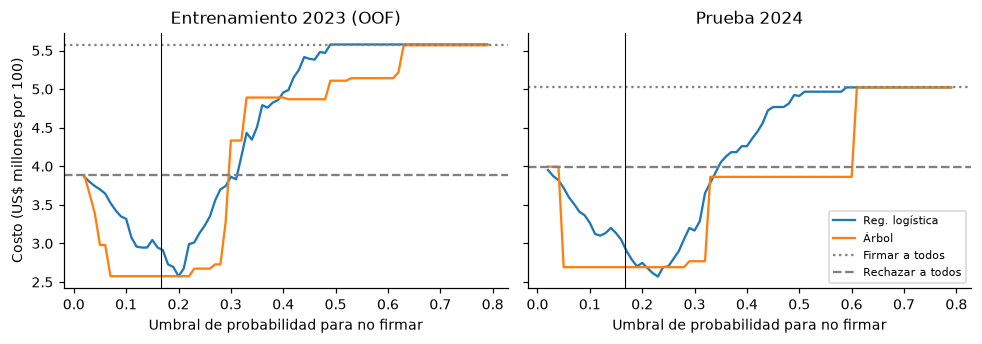

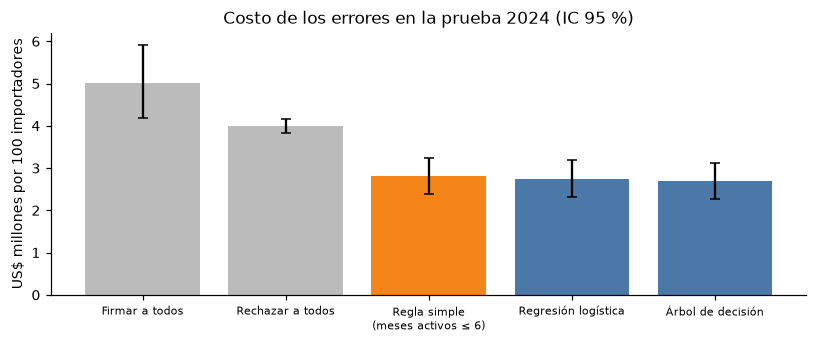

In [ ]:
# Curva de costo según el umbral (decisión binaria firmar / no firmar) — entrenamiento (OOF) y prueba
ts = np.round(np.arange(0.02, 0.8, 0.01), 2)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for a, (tit, y_, ps) in zip(ax, [("Entrenamiento 2023 (OOF)", ytr, {"Reg. logística": p_lr_oof, "Árbol": p_dt_oof}), ("Prueba 2024", yte, {"Reg. logística": p_lr_te, "Árbol": p_dt_te})]):
    for nom, p in ps.items():
        a.plot(ts, [costo100(y_, np.where(p >= t, 2, 0)) / 1e6 for t in ts], label=nom)
    a.axhline(costo100(y_, np.zeros(len(y_))) / 1e6, ls=":", c="gray", label="Firmar a todos")
    a.axhline(costo100(y_, np.full(len(y_), 2)) / 1e6, ls="--", c="gray", label="Rechazar a todos")
    a.axvline(T_BIN_TEO, c="k", lw=.7); a.set_title(tit); a.set_xlabel("Umbral de probabilidad para no firmar")
ax[0].set_ylabel("Costo (US$ millones por 100)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("figs/f6_curva_costo.png", dpi=160); plt.show()

# Barras de costo con intervalo
fig, ax = plt.subplots(figsize=(7.5, 3.2))
orden = tabla.iloc[[0, 1, 2, 3, 4]]
ax.bar(range(len(orden)), orden.costo_100 / 1e6, yerr=[(orden.costo_100 - orden.ic_lo) / 1e6, (orden.ic_hi - orden.costo_100) / 1e6], capsize=3, color=["#bbb", "#bbb", "#f58518", "#4c78a8", "#4c78a8"])
ax.set_xticks(range(len(orden))); ax.set_xticklabels([s.replace(" (", "\n(") for s in orden.estrategia], fontsize=7)
ax.set_ylabel("US$ millones por 100 importadores"); ax.set_title("Costo de los errores en la prueba 2024 (IC 95 %)")
plt.tight_layout(); plt.savefig("figs/f7_costo_estrategias.png", dpi=160); plt.show()

**Conclusión de la evaluación (prueba 2024, 453 importadores, 91 abandonan).**
- Las dos decisiones triviales son caras: firmar a todos cuesta US$5,02 M por 100 importadores y rechazar a todos US$4,00 M.
- La **regla simple** (no firmar con quienes importaron ≤ 6 meses; corte ajustado con 2023) baja el costo a **US$2,81 M**: ahorra US$1,18 M frente a la mejor decisión trivial (IC 95 % de la diferencia: US$0,65–1,66 M).
- Los modelos quedan ligeramente por debajo de la regla: regresión logística US$2,75 M y árbol US$2,69 M. Pero la diferencia contra la regla es de apenas US$66 mil y US$121 mil por 100 importadores, y **los intervalos de la diferencia incluyen el cero** (−420 mil a +320 mil y −409 mil a +143 mil). **No podemos afirmar que el modelo le gana a la regla simple.** Con ~91 abandonos en la prueba los intervalos son anchos.
- El AUC de la logística en prueba es 0,76: ordena razonablemente el riesgo, pero esa información adicional todavía no se traduce en ahorros demostrables frente a la regla. Eso es un hallazgo, no un fracaso: hoy una regla de una frase captura casi todo el valor.

## 7. Índice de arraigo importador
Para el resumen ejecutivo, el equipo define el **índice de arraigo importador = 100 × (1 − probabilidad de abandono)** según la regresión logística: 100 significa que el importador casi seguro sostendrá sus compras (≥ 50 % de las del año actual) el año siguiente; 0, que casi seguro las recorta a menos de la mitad.

In [ ]:
p_ar = p_lr_te                      # la regresión logística da probabilidades graduadas (el árbol de 2 niveles solo da 4 valores)
arraigo = 100 * (1 - p_ar)
dec_s = decidir(p_ar, T1_TEO, T2_TEO)   # tres zonas con los umbrales teóricos
resumen = pd.DataFrame({"arraigo": arraigo, "decision": [NOMBRE_DEC[d] for d in dec_s], "abandona": yte})
r = resumen.groupby("decision").agg(n=("arraigo", "size"), arraigo_medio=("arraigo", "mean"), tasa_abandono=("abandona", "mean"))
print(f"Arraigo medio de los {len(yte)} importadores de prueba: {arraigo.mean():.1f} (mediana {np.median(arraigo):.1f}; rango {arraigo.min():.0f}-{arraigo.max():.0f})")
print(r.round(3).to_string())
print("Zonas por arraigo: firmar si arraigo > %.1f; garantías entre %.1f y %.1f; no firmar si < %.1f" % (100*(1-T1_TEO), 100*(1-T2_TEO), 100*(1-T1_TEO), 100*(1-T2_TEO)))
RES["arraigo"] = {"medio": float(arraigo.mean()), "mediana": float(np.median(arraigo)), "por_decision": r.round(4).to_dict("index")}

Arraigo medio de los 453 importadores de prueba: 78.4 (mediana 79.1; rango 41-99)
                        n  arraigo_medio  tasa_abandono
decision                                               
Firmar                116             92          0.052
Firmar con garantías   99             83          0.111
No firmar             238             70          0.311
Zonas por arraigo: firmar si arraigo > 86.7; garantías entre 80.0 y 86.7; no firmar si < 80.0


**Lectura.** El arraigo medio de los 453 importadores de prueba es 78,4. Los tres tramos de decisión se ordenan como debe ser: con arraigo alto (≈92, 116 importadores) abandonó solo el 5,2 %; en la zona de garantías (≈83, 99 importadores) el 11,1 %; y en la zona de no firmar (≈70, 238 importadores) el 31,1 %. *Para Seoru:* el índice permite explicar la recomendación sin jerga. Un arraigo bajo no es una sentencia: 2 de cada 3 importadores en la zona "no firmar" sí se habrían quedado, y por eso el costo de rechazar de más (US$50 mil por caso) pesa en la cuenta.

## 8. Guardar resultados

In [ ]:
def _s(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)
with open("resultados_entrega1.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=1, default=_s)
tabla.to_csv("tabla_evaluacion.csv", index=False)
print("Listo: resultados_entrega1.json, tabla_evaluacion.csv y figs/*.png")

Listo: resultados_entrega1.json, tabla_evaluacion.csv y figs/*.png
